In [1]:
# ==========================================================
# STEP 1 | CELL 1: INSTALL REQUIRED PACKAGES
# Purpose: Install the Python libraries used in this project.
# ==========================================================

%pip install -q numpy pandas matplotlib seaborn scikit-learn requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ==========================================================
# STEP 2 | CELL 2: IMPORT REQUIRED LIBRARIES
# Purpose: Import all libraries needed for the project.
# ==========================================================

import os
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
import joblib

sns.set_theme(style="whitegrid")
print("All libraries imported successfully.")

All libraries imported successfully.


In [3]:
# ==========================================================
# STEP 3 | CELL 3: LOAD UPLOADED DATASET FILES
# Purpose: Read the uploaded feature names and activity labels.
# No downloading, ZIP extraction, or folder searching.
# ==========================================================

import pandas as pd

# Load the uploaded feature names file
features = pd.read_csv(
    "features.txt",
    sep=r"\s+",
    header=None,
    names=["index", "feature_name"]
)

# Load the uploaded activity labels file
activity_labels = pd.read_csv(
    "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity_name"]
)

# Store feature names and activity names
feature_names = features["feature_name"].tolist()

activity_names = activity_labels["activity_name"].tolist()

# Display results
print("Feature file loaded successfully!")
print("Total features:", len(feature_names))

print("\nActivity labels loaded successfully!")
display(activity_labels)

Feature file loaded successfully!
Total features: 561

Activity labels loaded successfully!


,activity_id,activity_name
0,1,WALKING
1,2,WALKING_UPSTAIRS
2,3,WALKING_DOWNSTAIRS
3,4,SITTING
4,5,STANDING
5,6,LAYING


In [4]:
# ==========================================================
# STEP 4 | CELL 4: LOAD FEATURE NAMES AND ACTIVITY LABELS
# Purpose: Read the uploaded feature and activity label files.
# ==========================================================

import pandas as pd

# Load the 561 feature names directly
features = pd.read_csv(
    "features.txt",
    sep=r"\s+",
    header=None,
    names=["index", "feature_name"]
)

# Load the six activity labels directly
activity_labels = pd.read_csv(
    "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity_name"]
)

# Extract feature names
feature_names = features["feature_name"].tolist()

# Extract activity names
activity_names = activity_labels["activity_name"].tolist()

# Create activity ID mapping
activity_map = dict(zip(
    activity_labels["activity_id"],
    activity_labels["activity_name"]
))

# Display results
print("FEATURE INFORMATION")
print("-------------------")
print("Total number of features:", len(feature_names))

print("\nACTIVITY INFORMATION")
print("--------------------")
print("Total number of activities:", len(activity_names))

display(activity_labels)

print("\nFirst 10 feature names:")
display(features.head(10))

print("\nStep 4 completed successfully!")

FEATURE INFORMATION
-------------------
Total number of features: 561

ACTIVITY INFORMATION
--------------------
Total number of activities: 6


,activity_id,activity_name
0,1,WALKING
1,2,WALKING_UPSTAIRS
2,3,WALKING_DOWNSTAIRS
3,4,SITTING
4,5,STANDING
5,6,LAYING



First 10 feature names:


,index,feature_name
0,1,tBodyAcc-mean()-X
1,2,tBodyAcc-mean()-Y
2,3,tBodyAcc-mean()-Z
3,4,tBodyAcc-std()-X
4,5,tBodyAcc-std()-Y
5,6,tBodyAcc-std()-Z
6,7,tBodyAcc-mad()-X
7,8,tBodyAcc-mad()-Y
8,9,tBodyAcc-mad()-Z
9,10,tBodyAcc-max()-X



Step 4 completed successfully!


In [6]:
# ==========================================================
# STEP 4 | CELL 4: LOAD FEATURE NAMES AND ACTIVITY LABELS
# Purpose: Load feature names and handle duplicate column names.
# ==========================================================

import pandas as pd

# Load feature names directly
features = pd.read_csv(
    "features.txt",
    sep=r"\s+",
    header=None,
    names=["index", "feature_name"]
)

# Identify duplicate feature names
duplicate_count = features["feature_name"].duplicated().sum()

print("Total features:", len(features))
print("Duplicate feature names:", duplicate_count)

# Make duplicate feature names unique
feature_names = features["feature_name"].copy()

feature_names = (
    feature_names.groupby(feature_names)
    .transform(
        lambda x: [
            name if i == 0 else f"{name}_{i}"
            for i, name in enumerate(x)
        ]
    )
    .tolist()
)

# Load activity labels
activity_labels = pd.read_csv(
    "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity_name"]
)

# Store activity names
activity_names = activity_labels["activity_name"].tolist()

# Create activity ID mapping
activity_map = dict(zip(
    activity_labels["activity_id"],
    activity_labels["activity_name"]
))

# Display results
print("\nUnique feature names:", len(set(feature_names)))
print("Activity classes:", len(activity_names))

print("\nActivity labels:")
display(activity_labels)

print("\nFirst 10 feature names:")
display(pd.DataFrame({"Feature": feature_names[:10]}))

print("\nStep 4 completed successfully!")

Total features: 561
Duplicate feature names: 84

Unique feature names: 561
Activity classes: 6

Activity labels:


,activity_id,activity_name
0,1,WALKING
1,2,WALKING_UPSTAIRS
2,3,WALKING_DOWNSTAIRS
3,4,SITTING
4,5,STANDING
5,6,LAYING



First 10 feature names:


,Feature
0,tBodyAcc-mean()-X
1,tBodyAcc-mean()-Y
2,tBodyAcc-mean()-Z
3,tBodyAcc-std()-X
4,tBodyAcc-std()-Y
5,tBodyAcc-std()-Z
6,tBodyAcc-mad()-X
7,tBodyAcc-mad()-Y
8,tBodyAcc-mad()-Z
9,tBodyAcc-max()-X



Step 4 completed successfully!


In [7]:
# ==========================================================
# STEP 5 | CELL 5: LOAD TRAINING AND TESTING DATA
# Purpose: Load the four uploaded dataset files directly.
# ==========================================================

# Load training features
X_train = pd.read_csv(
    "X_train.txt",
    sep=r"\s+",
    header=None
)

# Load testing features
X_test = pd.read_csv(
    "X_test.txt",
    sep=r"\s+",
    header=None
)

# Assign unique feature names created in Step 4
X_train.columns = feature_names
X_test.columns = feature_names

# Load training activity labels
y_train = pd.read_csv(
    "y_train.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id"]
)["activity_id"]

# Load testing activity labels
y_test = pd.read_csv(
    "y_test.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id"]
)["activity_id"]

# Convert activity IDs into activity names
y_train_names = y_train.map(activity_map)
y_test_names = y_test.map(activity_map)

# Display dataset dimensions
print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels :", y_test.shape)

print("\nDataset loaded successfully!")

Training features: (7352, 561)
Testing features : (2947, 561)
Training labels: (7352,)
Testing labels : (2947,)

Dataset loaded successfully!


In [8]:
# ==========================================================
# STEP 6 | CELL 6: BASIC DATASET EXPLORATION
# Purpose: Understand the structure and values of the dataset.
# ==========================================================

# Display first five observations
display(X_train.head())

# Display dataset information
print("Dataset Information:")
X_train.info()

# Display statistical summary
print("\nStatistical Summary:")
display(X_train.describe())

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 561 entries, tBodyAcc-mean()-X to angle(Z,gravityMean)
dtypes: float64(561)
memory usage: 31.5 MB

Statistical Summary:


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
count,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,...,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000
mean,0.274488,-0.017695,-0.109141,-0.605438,-0.510938,-0.604754,-0.630512,-0.526907,-0.606150,-0.468604,...,0.125293,-0.307009,-0.625294,0.008684,0.002186,0.008726,-0.005981,-0.489547,0.058593,-0.056515
std,0.070261,0.040811,0.056635,0.448734,0.502645,0.418687,0.424073,0.485942,0.414122,0.544547,...,0.250994,0.321011,0.307584,0.336787,0.448306,0.608303,0.477975,0.511807,0.297480,0.279122
min,-1.000000,-1.000000,-1.000000,-1.000000,-0.999873,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-0.995357,-0.999765,-0.976580,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,0.262975,-0.024863,-0.120993,-0.992754,-0.978129,-0.980233,-0.993591,-0.978162,-0.980251,-0.936219,...,-0.023692,-0.542602,-0.845573,-0.121527,-0.289549,-0.482273,-0.376341,-0.812065,-0.017885,-0.143414
50%,0.277193,-0.017219,-0.108676,-0.946196,-0.851897,-0.859365,-0.950709,-0.857328,-0.857143,-0.881637,...,0.134000,-0.343685,-0.711692,0.009509,0.008943,0.008735,-0.000368,-0.709417,0.182071,0.003181
75%,0.288461,-0.010783,-0.097794,-0.242813,-0.034231,-0.262415,-0.292680,-0.066701,-0.265671,-0.017129,...,0.289096,-0.126979,-0.503878,0.150865,0.292861,0.506187,0.359368,-0.509079,0.248353,0.107659
max,1.000000,1.000000,1.000000,1.000000,0.916238,1.000000,1.000000,0.967664,1.000000,1.000000,...,0.946700,0.989538,0.956845,1.000000,1.000000,0.998702,0.996078,1.000000,0.478157,1.000000


In [9]:
# ==========================================================
# STEP 7 | CELL 7: CHECK DATA QUALITY
# Purpose: Identify missing values and duplicate observations.
# ==========================================================

print("Missing values in training data:",
      X_train.isnull().sum().sum())

print("Missing values in testing data:",
      X_test.isnull().sum().sum())

print("Duplicate rows in training data:",
      X_train.duplicated().sum())

print("Duplicate rows in testing data:",
      X_test.duplicated().sum())

print("\nTraining data contains finite values:",
      np.isfinite(X_train.to_numpy()).all())

print("Testing data contains finite values:",
      np.isfinite(X_test.to_numpy()).all())

Missing values in training data: 0
Missing values in testing data: 0
Duplicate rows in training data: 0
Duplicate rows in testing data: 0

Training data contains finite values: True
Testing data contains finite values: True


,Training,Testing
activity_id,,
WALKING,1226,496
WALKING_UPSTAIRS,1073,471
WALKING_DOWNSTAIRS,986,420
SITTING,1286,491
STANDING,1374,532
LAYING,1407,537


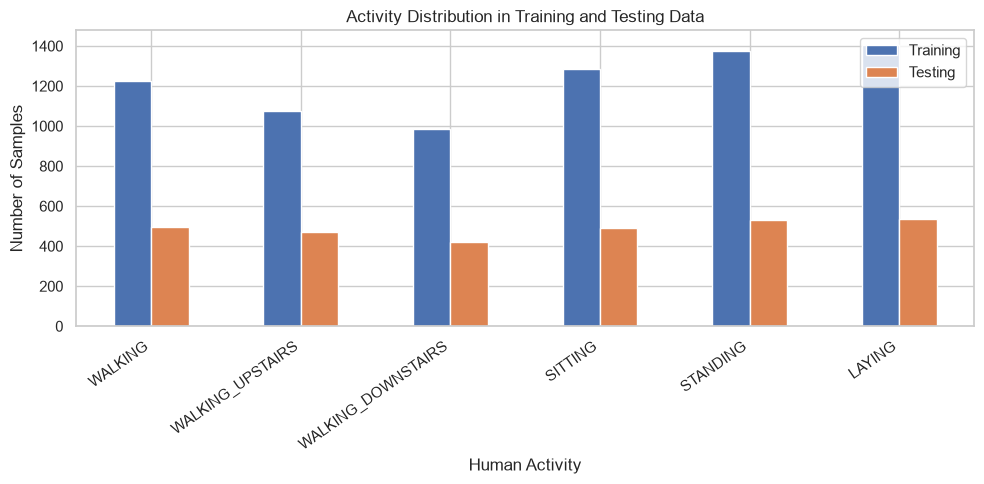

In [10]:
# ==========================================================
# STEP 8 | CELL 8: ACTIVITY CLASS DISTRIBUTION
# Purpose: Visualize the number of observations per activity.
# ==========================================================

train_counts = y_train_names.value_counts().reindex(activity_names)

test_counts = y_test_names.value_counts().reindex(activity_names)

distribution = pd.DataFrame({
    "Training": train_counts,
    "Testing": test_counts
})

display(distribution)

distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Activity Distribution in Training and Testing Data")
plt.xlabel("Human Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

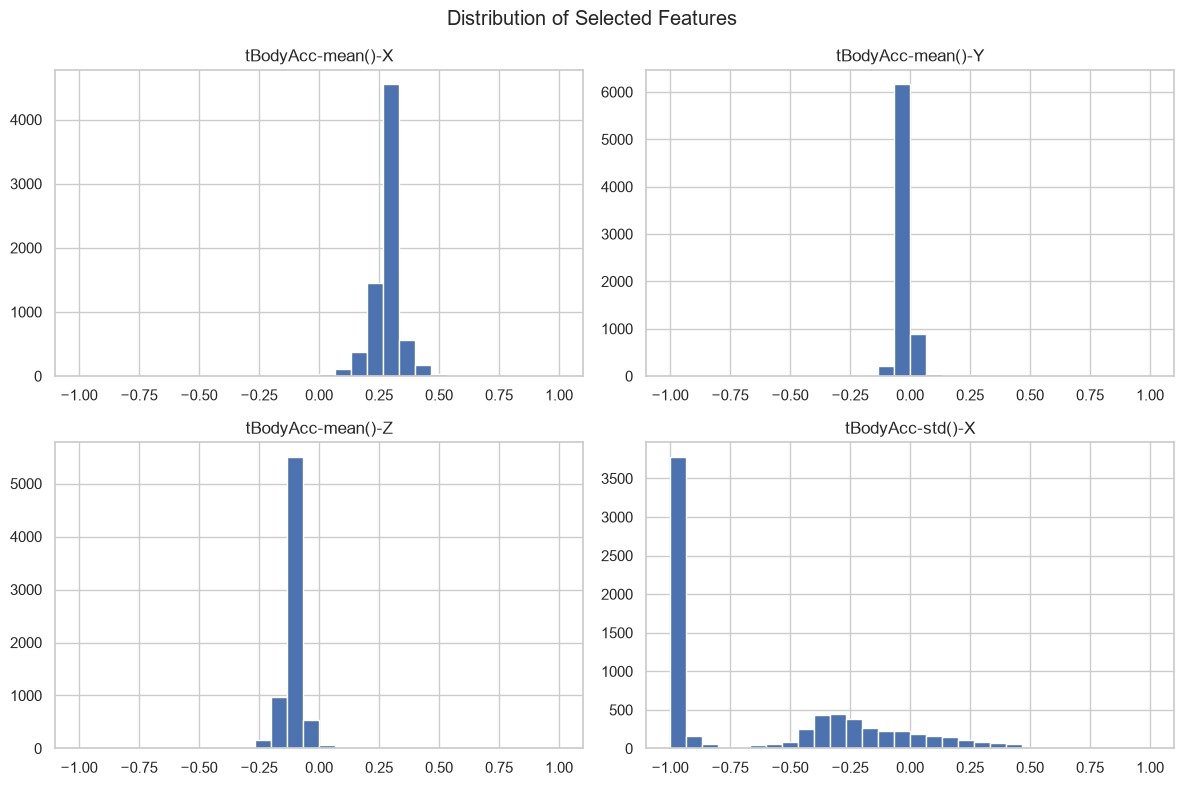

In [11]:
# ==========================================================
# STEP 9 | CELL 9: FEATURE DISTRIBUTION
# Purpose: Visualize the distribution of selected features.
# ==========================================================

selected_features = feature_names[:4]

X_train[selected_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle("Distribution of Selected Features")
plt.tight_layout()
plt.show()

In [12]:
# ==========================================================
# STEP 10 | CELL 10: PREPARE DATA FOR MODEL TRAINING
# Purpose: Separate input features and target labels.
# ==========================================================

X_train_model = X_train.copy()
X_test_model = X_test.copy()

y_train_model = y_train.copy()
y_test_model = y_test.copy()

print("Training data:", X_train_model.shape)
print("Testing data :", X_test_model.shape)

print("\nActivity classes:", sorted(y_train_model.unique()))

Training data: (7352, 561)
Testing data : (2947, 561)

Activity classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [13]:
# ==========================================================
# STEP 11 | CELL 11: K-NEAREST NEIGHBORS CLASSIFICATION
# Purpose: Train KNN and predict human activities.
# ==========================================================

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn_model.fit(X_train_model, y_train_model)

# Predict testing data
knn_predictions = knn_model.predict(X_test_model)

print("KNN model trained successfully!")

KNN model trained successfully!


In [14]:
# ==========================================================
# STEP 12 | CELL 12: DECISION TREE CLASSIFICATION
# Purpose: Train a Decision Tree classifier.
# ==========================================================

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
decision_tree_model.fit(X_train_model, y_train_model)

# Predict testing data
decision_tree_predictions = decision_tree_model.predict(X_test_model)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [15]:
# ==========================================================
# STEP 13 | CELL 13: RANDOM FOREST CLASSIFICATION
# Purpose: Train a Random Forest classifier.
# ==========================================================

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest_model.fit(X_train_model, y_train_model)

# Predict testing data
random_forest_predictions = random_forest_model.predict(X_test_model)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [16]:
# ==========================================================
# STEP 14 | CELL 14: MODEL PERFORMANCE EVALUATION
# Purpose: Calculate accuracy, precision, recall and F1-score.
# ==========================================================

predictions = {
    "KNN": knn_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions
}

results = []

for model_name, model_predictions in predictions.items():

    results.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_test_model, model_predictions
        ),

        "Precision": precision_score(
            y_test_model, model_predictions,
            average="macro"
        ),

        "Recall": recall_score(
            y_test_model, model_predictions,
            average="macro"
        ),

        "F1-score": f1_score(
            y_test_model, model_predictions,
            average="macro"
        )
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score
Model,,,,
KNN,0.8802,0.8897,0.8746,0.8766
Decision Tree,0.8622,0.8625,0.8587,0.8595
Random Forest,0.9287,0.9300,0.9258,0.9270


In [17]:
# ==========================================================
# STEP 15 | CELL 15: DETAILED CLASSIFICATION REPORT
# Purpose: Evaluate each activity separately.
# ==========================================================

for model_name, model_predictions in predictions.items():

    print("\n======================================")
    print("MODEL:", model_name)
    print("======================================")

    print(classification_report(
        y_test_model,
        model_predictions,
        target_names=activity_names
    ))


MODEL: KNN
                    precision    recall  f1-score   support

           WALKING       0.82      0.97      0.89       496
  WALKING_UPSTAIRS       0.88      0.90      0.89       471
WALKING_DOWNSTAIRS       0.96      0.73      0.83       420
           SITTING       0.88      0.76      0.82       491
          STANDING       0.80      0.93      0.86       532
            LAYING       1.00      0.95      0.97       537

          accuracy                           0.88      2947
         macro avg       0.89      0.87      0.88      2947
      weighted avg       0.89      0.88      0.88      2947


MODEL: Decision Tree
                    precision    recall  f1-score   support

           WALKING       0.83      0.92      0.87       496
  WALKING_UPSTAIRS       0.83      0.78      0.80       471
WALKING_DOWNSTAIRS       0.89      0.83      0.86       420
           SITTING       0.83      0.76      0.80       491
          STANDING       0.80      0.86      0.83       532
  

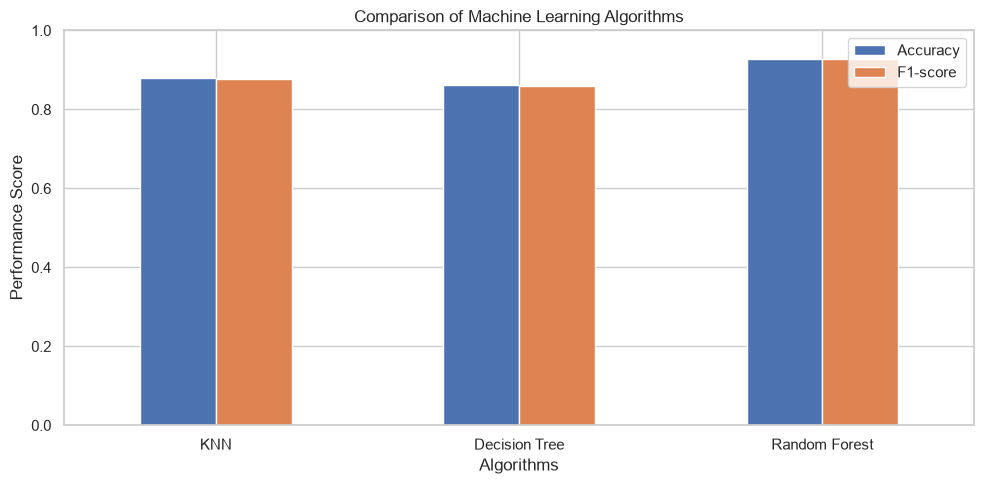

In [18]:
# ==========================================================
# STEP 16 | CELL 16: MODEL COMPARISON GRAPH
# Purpose: Compare the accuracy and F1-score of all models.
# ==========================================================

results_df[["Accuracy", "F1-score"]].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1)
)

plt.title("Comparison of Machine Learning Algorithms")
plt.xlabel("Algorithms")
plt.ylabel("Performance Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

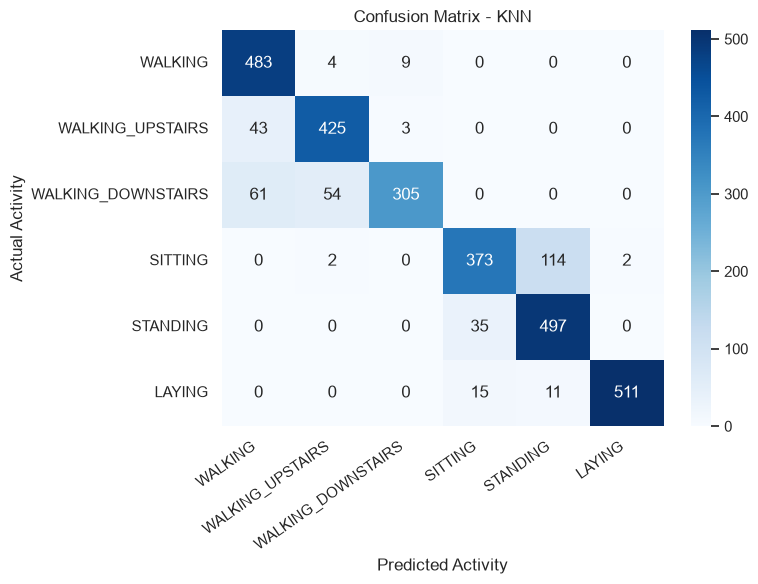

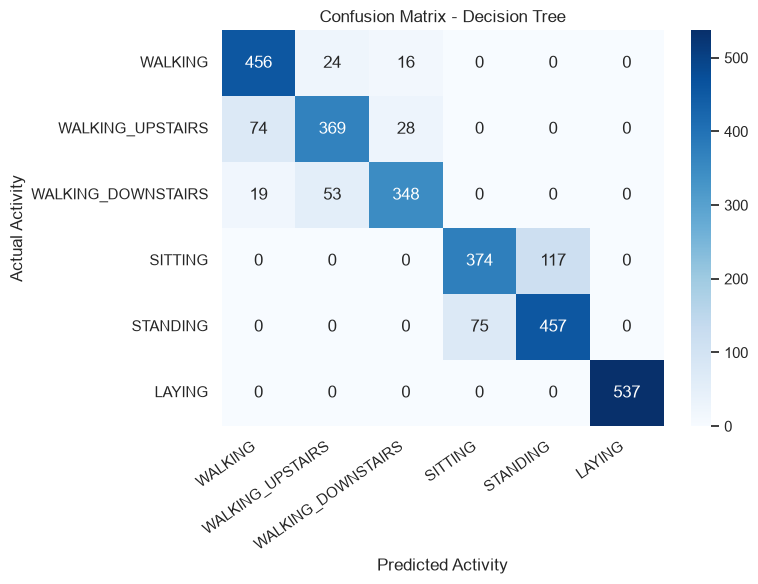

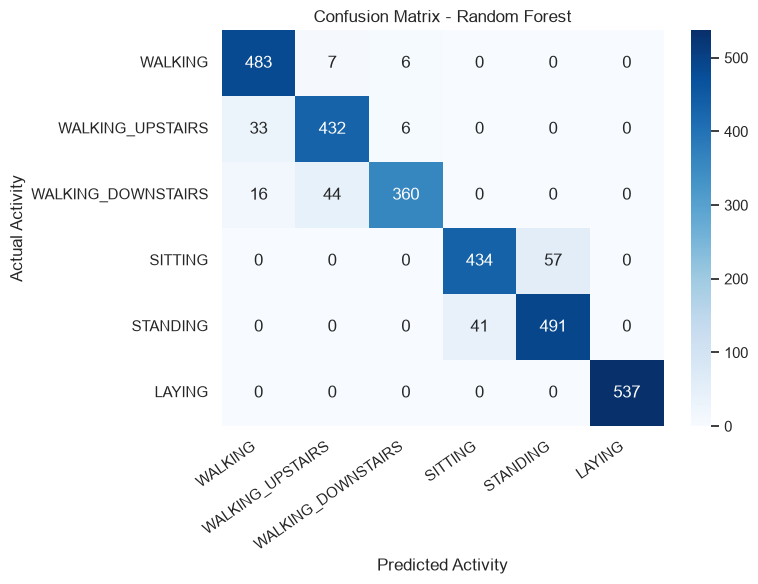

In [19]:
# ==========================================================
# STEP 17 | CELL 17: CONFUSION MATRIX
# Purpose: Visualize correctly and incorrectly classified activities.
# ==========================================================

for model_name, model_predictions in predictions.items():

    cm = confusion_matrix(
        y_test_model,
        model_predictions
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=activity_names,
        yticklabels=activity_names
    )

    plt.title("Confusion Matrix - " + model_name)
    plt.xlabel("Predicted Activity")
    plt.ylabel("Actual Activity")

    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

,Feature,Importance
40,tGravityAcc-mean()-X,0.038503
52,tGravityAcc-min()-X,0.030483
41,tGravityAcc-mean()-Y,0.029229
558,"angle(X,gravityMean)",0.027734
56,tGravityAcc-energy()-X,0.024915
559,"angle(Y,gravityMean)",0.022510
53,tGravityAcc-min()-Y,0.022276
50,tGravityAcc-max()-Y,0.021444
49,tGravityAcc-max()-X,0.021429
57,tGravityAcc-energy()-Y,0.017325


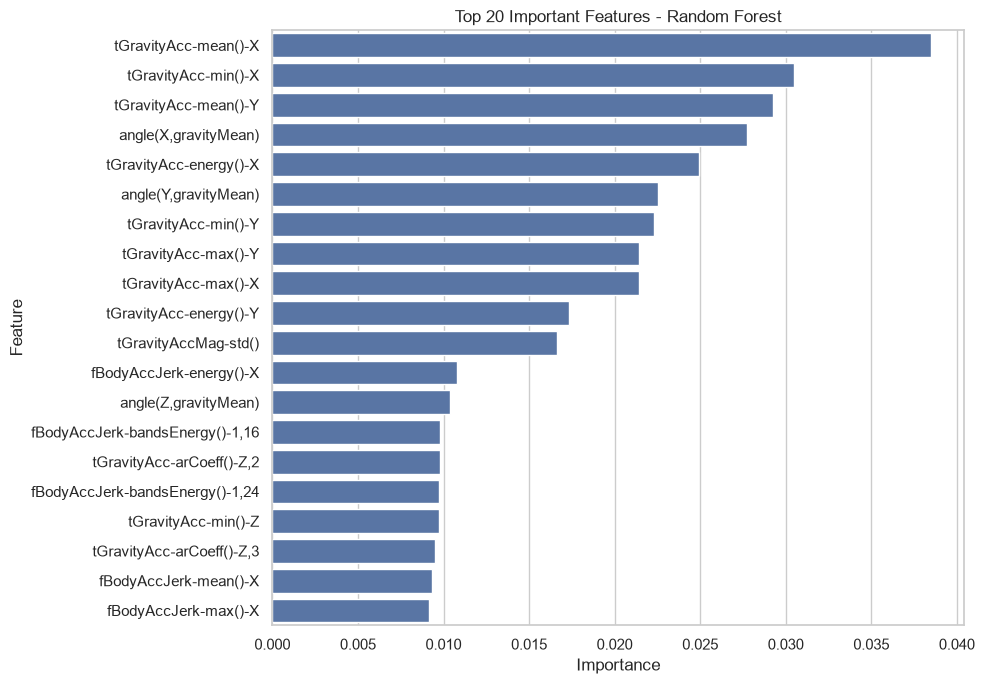

In [20]:
# ==========================================================
# STEP 18 | CELL 18: FEATURE IMPORTANCE ANALYSIS
# Purpose: Identify the most important input features.
# ==========================================================

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": random_forest_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

top_20_features = importance_df.head(20)

display(top_20_features)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_20_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Important Features - Random Forest")
plt.tight_layout()
plt.show()

In [21]:
# ==========================================================
# STEP 19 | CELL 19: BEST MODEL SELECTION
# Purpose: Select the model with the highest macro F1-score.
# ==========================================================

best_model_name = results_df["F1-score"].idxmax()

best_score = results_df.loc[
    best_model_name, "F1-score"
]

print("Best Performing Model:", best_model_name)
print("Best Macro F1-score:", round(best_score, 4))

display(
    results_df.sort_values(
        by="F1-score",
        ascending=False
    ).round(4)
)

Best Performing Model: Random Forest
Best Macro F1-score: 0.927


,Accuracy,Precision,Recall,F1-score
Model,,,,
Random Forest,0.9287,0.9300,0.9258,0.9270
KNN,0.8802,0.8897,0.8746,0.8766
Decision Tree,0.8622,0.8625,0.8587,0.8595


In [22]:
# ==========================================================
# STEP 20 | CELL 20: SAVE TRAINED MODELS
# Purpose: Save the trained models for future use.
# ==========================================================

import joblib
import os

os.makedirs("saved_models", exist_ok=True)

joblib.dump(
    knn_model,
    "saved_models/knn_har_model.pkl"
)

joblib.dump(
    decision_tree_model,
    "saved_models/decision_tree_har_model.pkl"
)

joblib.dump(
    random_forest_model,
    "saved_models/random_forest_har_model.pkl"
)

print("All trained models saved successfully!")

All trained models saved successfully!


In [23]:
# ==========================================================
# STEP 21 | CELL 21: SINGLE ACTIVITY PREDICTION
# Purpose: Predict the activity of one testing observation.
# ==========================================================

sample_index = 0

sample_features = X_test_model.iloc[[sample_index]]

actual_activity_id = y_test_model.iloc[sample_index]

predicted_activity_id = random_forest_model.predict(
    sample_features
)[0]

print("Actual Activity:",
      activity_map[actual_activity_id])

print("Predicted Activity:",
      activity_map[predicted_activity_id])

Actual Activity: STANDING
Predicted Activity: STANDING


In [24]:
# ==========================================================
# STEP 22 | CELL 22: FINAL PROJECT SUMMARY
# Purpose: Display the final model comparison and results.
# ==========================================================

print("HUMAN ACTIVITY RECOGNITION PROJECT")
print("=" * 50)

print("Training Samples:", len(X_train_model))
print("Testing Samples :", len(X_test_model))
print("Total Features  :", X_train_model.shape[1])
print("Activity Classes:", len(activity_names))

print("\nMODEL PERFORMANCE")
display(results_df.round(4))

print("\nBEST MODEL:", best_model_name)
print("BEST MACRO F1-SCORE:", round(best_score, 4))

print("\nPROJECT EXECUTION COMPLETED!")

HUMAN ACTIVITY RECOGNITION PROJECT
Training Samples: 7352
Testing Samples : 2947
Total Features  : 561
Activity Classes: 6

MODEL PERFORMANCE


,Accuracy,Precision,Recall,F1-score
Model,,,,
KNN,0.8802,0.8897,0.8746,0.8766
Decision Tree,0.8622,0.8625,0.8587,0.8595
Random Forest,0.9287,0.9300,0.9258,0.9270



BEST MODEL: Random Forest
BEST MACRO F1-SCORE: 0.927

PROJECT EXECUTION COMPLETED!


In [26]:
# ==========================================================
# STEP 23 | CELL 23: EXPORT MODELS FOR WEB APPLICATION
# Purpose: Save trained models and dataset information
#          required by the Streamlit web application.
# ==========================================================

import os
import json
import joblib
from pathlib import Path

# Create artifacts directory
if Path("HAR_Web_App").exists():
    ARTIFACT_DIR = Path("HAR_Web_App") / "artifacts"
else:
    ARTIFACT_DIR = Path("artifacts")

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Save trained models
joblib.dump(
    knn_model,
    ARTIFACT_DIR / "knn_har_model.pkl"
)

joblib.dump(
    decision_tree_model,
    ARTIFACT_DIR / "decision_tree_har_model.pkl"
)

joblib.dump(
    random_forest_model,
    ARTIFACT_DIR / "random_forest_har_model.pkl"
)

# Save testing data
X_test.to_csv(
    ARTIFACT_DIR / "X_test.csv",
    index=False
)

y_test.to_frame().to_csv(
    ARTIFACT_DIR / "y_test.csv",
    index=False
)

# Save feature importance
importance_df.to_csv(
    ARTIFACT_DIR / "feature_importance.csv",
    index=False
)

# Save evaluation metrics and project metadata
metadata = {
    "feature_names": feature_names,
    "activity_map": {
        str(k): v for k, v in activity_map.items()
    },
    "results": results_df.to_dict(orient="index"),
    "best_model": best_model_name,
    "training_samples": len(X_train),
    "testing_samples": len(X_test),
    "number_of_features": len(feature_names)
}

with open(
    ARTIFACT_DIR / "metadata.json",
    "w"
) as file:
    json.dump(metadata, file, indent=4)

print("WEB APPLICATION FILES EXPORTED SUCCESSFULLY!")
print("Saved location:", ARTIFACT_DIR)

print("\nExported files:")
for file in ARTIFACT_DIR.iterdir():
    print(file.name)

WEB APPLICATION FILES EXPORTED SUCCESSFULLY!
Saved location: artifacts

Exported files:
decision_tree_har_model.pkl
feature_importance.csv
knn_har_model.pkl
metadata.json
random_forest_har_model.pkl
X_test.csv
y_test.csv


In [27]:
# STEP 24 | CELL 24: CHECK ARTIFACTS LOCATION

import os

print("Notebook working directory:", os.getcwd())
print("Artifacts folder exists:", os.path.exists("artifacts"))
print("Artifacts full path:", os.path.abspath("artifacts"))

Notebook working directory: C:\Users\hrish\Desktop\NIT\DSF
Artifacts folder exists: True
Artifacts full path: C:\Users\hrish\Desktop\NIT\DSF\artifacts
